# **Лабораторная 1. Иерархический кластерный анализ**

> - **Предмет**: Математические методы анализа экономических процессов
> - **Студент**: Руденко Андрей Артемович
> - **Группа**: М9125-01.04.02МКТ

## Цель работы
1. Провести пошаговую кластеризацию набора данных
2. Проанализировать методом иерархической кластеризации набор ruspini

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

## 1.1. Пошаговая кластеризация набора данных

### Данные *(Вариант 16)*

In [2]:
data = pd.DataFrame({'X1': [19, 21, 34, 17], 'X2': [31, 33, 60, 37]}, index=[1, 2, 3, 4])
data.columns.name = 'Объект'
data

Объект,X1,X2
1,19,31
2,21,33
3,34,60
4,17,37


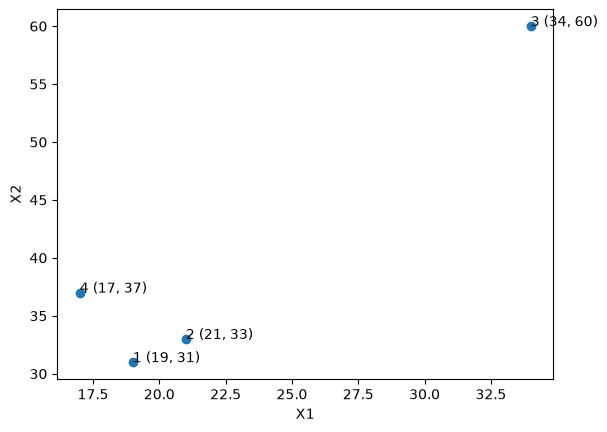

In [3]:
plt.scatter(data['X1'], data['X2'])
for i in data.index:
    plt.text(data['X1'][i], data['X2'][i], f"{i} ({data['X1'][i]}, {data['X2'][i]})")
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()

### Метрика расстояния

Для расстояния между объектами подойдёт евклидово расстояние, т.к. все признаки числовые, в одном масштабе и без резких выбросов.
$$d(i, j) = \sqrt{(X1_i - X1_j)^2 + (X2_i - X2_j)^2}$$

In [4]:
def euclid(i, j):
    return np.sqrt((data['X1'][i] - data['X1'][j])**2 + (data['X2'][i] - data['X2'][j])**2)

### Метод объединения объектов в кластеры

Беру метод ближайшего соседа, где расстояние между кластерами равно расстоянию между их самыми близкими объектами.
$$D(A, B) = \min_{i \in A,\ j \in B} d(i, j)$$

In [5]:
def cluster_dist(A, B):
    return min(euclid(i, j) for i in A for j in B)

### Пошаговая кластеризация

In [6]:
clusters = [[i] for i in data.index]
ids = list(range(len(data)))
merges = []
step = 1
print(clusters)
while len(clusters) > 1:
    min_dist = None
    for a in range(len(clusters)):
        for b in range(a + 1, len(clusters)):
            d = cluster_dist(clusters[a], clusters[b])
            if min_dist is None or d < min_dist[0]:
                min_dist = [d, a, b]
    d, a, b = min_dist
    print(f'Шаг: {step}. Объединяются {clusters[a]} и {clusters[b]} с расстоянием {d:.2f}')
    new_cluster = clusters[a] + clusters[b]
    merges.append([ids[a], ids[b], d, len(new_cluster)])
    del clusters[b], clusters[a]
    del ids[b], ids[a]
    clusters.append(new_cluster)
    ids.append(len(data) + len(merges) - 1)
    print(clusters)
    step += 1

[[1], [2], [3], [4]]
Шаг: 1. Объединяются [1] и [2] с расстоянием 2.83
[[3], [4], [1, 2]]
Шаг: 2. Объединяются [4] и [1, 2] с расстоянием 5.66
[[3], [4, 1, 2]]
Шаг: 3. Объединяются [3] и [4, 1, 2] с расстоянием 28.60
[[3, 4, 1, 2]]


### Дендрограмма

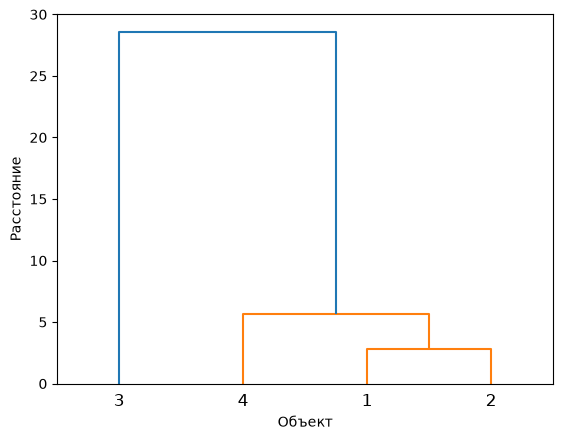

In [7]:
dendrogram(np.array(merges), labels=[str(i) for i in data.index])
plt.xlabel('Объект')
plt.ylabel('Расстояние')
plt.show()

### Результат

Объекты 1, 2 и 4 близки друг к другу и объединяются на расстояниях 2.83 и 5.66, объект 3 присоединяется только на 28.60. Самый большой скачок расстояния — на последнем шаге, поэтому данные делятся на 2 кластера: {1, 2, 4} и {3}.

## 1.2. Иерархическая кластеризация набора ruspini

### Данные

Набор ruspini из R-пакета cluster: 75 точек с двумя признаками x и y.

In [8]:
ruspini = pd.read_csv('https://vincentarelbundock.github.io/Rdatasets/csv/cluster/ruspini.csv', index_col=0)
ruspini.head()

,x,y
rownames,,
1,4,53
2,5,63
3,10,59
4,9,77
5,13,49


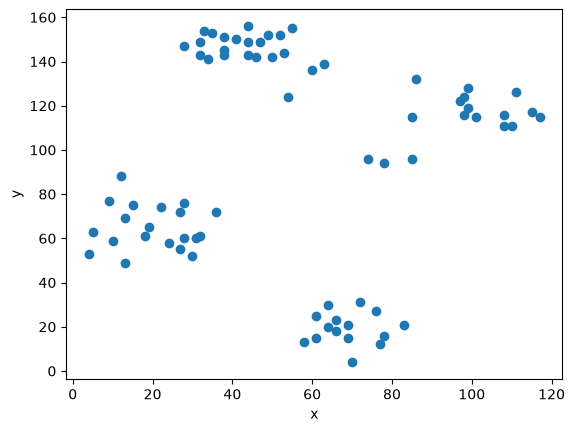

In [9]:
plt.scatter(ruspini['x'], ruspini['y'])
plt.xlabel('x')
plt.ylabel('y')
plt.show()

### Дендрограмма

Метрика — евклидово расстояние, метод объединения — дальнего соседа, т.к. на графике группы точек компактные.

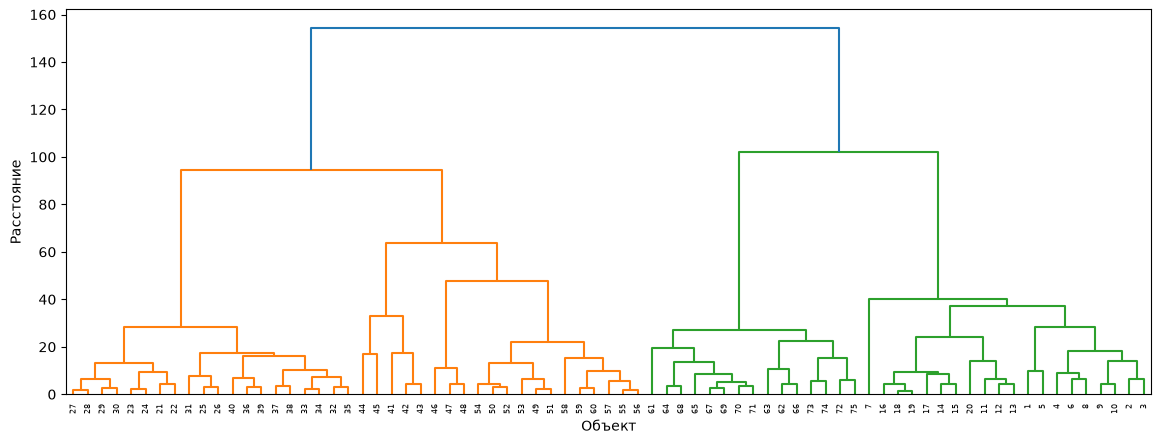

In [10]:
merges = linkage(ruspini[['x', 'y']], method='complete')

plt.figure(figsize=(14, 5))
dendrogram(merges, labels=list(ruspini.index))
plt.xlabel('Объект')
plt.ylabel('Расстояние')
plt.show()

### Разбиение на заданное число кластеров

Отсекаю дерево на уровне 4 кластеров: линия проходит между третьим и четвёртым с конца объединением.

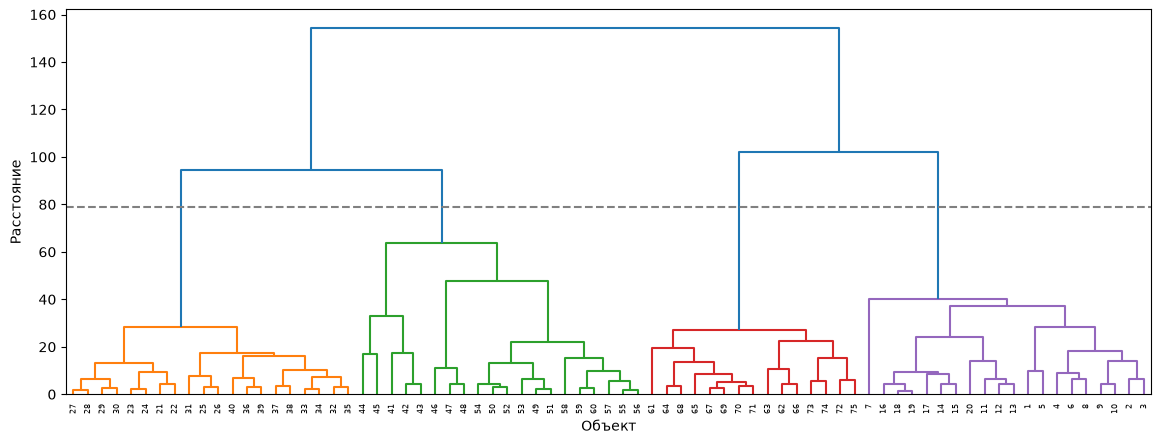

cluster
1    20
2    20
3    15
4    20
Name: count, dtype: int64

In [11]:
k = 4
cut = (merges[-k, 2] + merges[-k + 1, 2]) / 2
ruspini['cluster'] = fcluster(merges, k, criterion='maxclust')

plt.figure(figsize=(14, 5))
dendrogram(merges, labels=list(ruspini.index), color_threshold=cut)
plt.axhline(cut, color='gray', linestyle='--')
plt.xlabel('Объект')
plt.ylabel('Расстояние')
plt.show()

ruspini['cluster'].value_counts().sort_index()

### Кластеры на графике

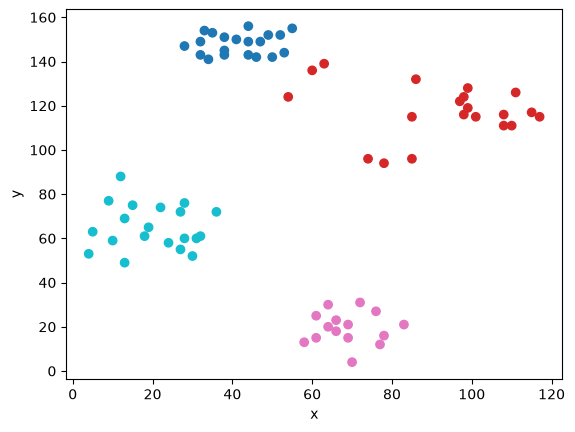

In [12]:
plt.scatter(ruspini['x'], ruspini['y'], c=ruspini['cluster'], cmap='tab10')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

### Объекты заданного кластера

In [13]:
ruspini[ruspini['cluster'] == 1]

,x,y,cluster
rownames,,,
21,28,147,1
22,32,149,1
23,35,153,1
24,33,154,1
25,38,151,1
26,41,150,1
27,38,145,1
28,38,143,1
29,32,143,1


### Статистики внутри кластеров

In [14]:
ruspini.groupby('cluster')[['x', 'y']].agg(['mean', 'median', 'min', 'max'])

x                       y                 
              mean median min  max    mean median  min  max
cluster                                                    
1        41.650000   42.5  28   55  148.00  149.0  141  156
2        92.300000   98.0  54  117  117.60  116.5   94  139
3        68.933333   69.0  58   83   19.40   20.0    4   31
4        20.150000   20.5   4   36   64.95   62.0   49   88

## Вывод

В пункте 1.1 пошаговая кластеризация методом ближайшего соседа разделила 4 объекта на 2 кластера: {1, 2, 4} и {3}.

В пункте 1.2 дендрограмма набора ruspini, построенная методом дальнего соседа, показывает 4 группы: между третьим и четвёртым с конца объединением большой разрыв по высоте, примерно от 64 до 95. При разрезе на 4 кластера получилось 20, 20, 15 и 20 объектов, и на диаграмме рассеяния они совпадают с видимыми группами точек. Самый разреженный — кластер 2: x от 54 до 117, y от 94 до 139, в него попали и три точки, лежащие между первым и вторым кластером.